<a href="https://colab.research.google.com/github/wgayo/CC-APPSDEV22-2026-GAYO-AdvancedCSharpLab/blob/main/Lab8_Supervised_Learning_GAYO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8: Supervised Learning Algorithms

## Fundamentals of Artificial Intelligence

**Name:** [Your Name]  
**Course:** [Your Course]  
**Section:** [Your Section]  
**Date:** [Date]  

**Dataset Sources:**
1. California Housing: `sklearn.datasets.fetch_california_housing`
2. Breast Cancer: `sklearn.datasets.load_breast_cancer`

**GitHub URL:** [Paste your GitHub URL here]

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

# Tools & Metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report, roc_curve, auc

# Datasets
from sklearn.datasets import fetch_california_housing, load_breast_cancer

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset
housing = fetch_california_housing()
X_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
y_housing = housing.target

# Split data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train_reg.shape}")
print(f"Testing set size: {X_test_reg.shape}")

Training set size: (16512, 8)
Testing set size: (4128, 8)


In [3]:
# Initialize and train
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)

# Predict
y_pred_reg = lin_reg.predict(X_test_reg)

# Evaluate
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("LINEAR REGRESSION RESULTS")
print("="*30)
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

LINEAR REGRESSION RESULTS
RMSE: 0.7456
R2 Score: 0.5758


### Interpreting the Weights

In [4]:
coefficients = pd.DataFrame({
    'Feature': X_housing.columns,
    'Coefficient (Weight)': lin_reg.coef_
}).sort_values(by='Coefficient (Weight)', key=abs, ascending=False)

print(coefficients)

      Feature  Coefficient (Weight)
3   AveBedrms              0.783145
0      MedInc              0.448675
7   Longitude             -0.433708
6    Latitude             -0.419792
2    AveRooms             -0.123323
1    HouseAge              0.009724
5    AveOccup             -0.003526
4  Population             -0.000002


In [5]:
# Load dataset
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target

# Split data
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_cancer, y_cancer, test_size=0.3, stratify=y_cancer, random_state=42
)

In [6]:
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000, random_state=42))
])

log_reg_pipeline.fit(X_train_log, y_train_log)
y_pred_log = log_reg_pipeline.predict(X_test_log)

print("LOGISTIC REGRESSION RESULTS")
print("="*30)
print(f"Accuracy: {accuracy_score(y_test_log, y_pred_log):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_log, y_pred_log, target_names=cancer.target_names))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.9883

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



Confusion Matrix:
[[ 63   1]
 [  1 106]]


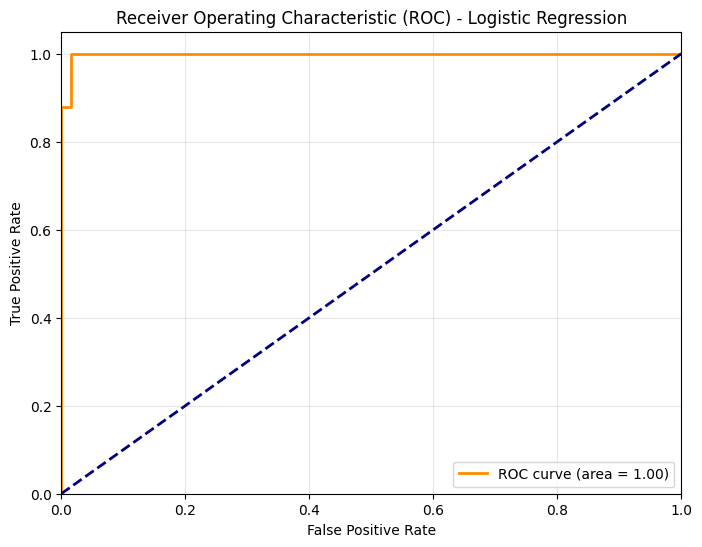

In [7]:
# Confusion Matrix
cm = confusion_matrix(y_test_log, y_pred_log)
print("Confusion Matrix:")
print(cm)

# ROC Curve
# Get probability scores for the positive class (Benign)
y_probs = log_reg_pipeline.predict_proba(X_test_log)[:, 1]
fpr, tpr, _ = roc_curve(y_test_log, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Logistic Regression')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Unpruned Tree (max_depth=None)
tree_unpruned = DecisionTreeClassifier(random_state=42)
tree_unpruned.fit(X_train_log, y_train_log)

train_acc_unpruned = accuracy_score(y_train_log, tree_unpruned.predict(X_train_log))
test_acc_unpruned = accuracy_score(y_test_log, tree_unpruned.predict(X_test_log))

print("UNPRUNED DECISION TREE")
print("="*30)
print(f"Training Accuracy: {train_acc_unpruned:.4f}")
print(f"Testing Accuracy:  {test_acc_unpruned:.4f}")
print(f"Tree Depth:        {tree_unpruned.get_depth()}")
print(f"Number of Leaves:  {tree_unpruned.get_n_leaves()}")

UNPRUNED DECISION TREE
Training Accuracy: 1.0000
Testing Accuracy:  0.9181
Tree Depth:        6
Number of Leaves:  16


In [9]:
# Pruned Tree (max_depth=3)
tree_pruned = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_pruned.fit(X_train_log, y_train_log)

train_acc_pruned = accuracy_score(y_train_log, tree_pruned.predict(X_train_log))
test_acc_pruned = accuracy_score(y_test_log, tree_pruned.predict(X_test_log))

print("\nPRUNED DECISION TREE (max_depth=3)")
print("="*30)
print(f"Training Accuracy: {train_acc_pruned:.4f}")
print(f"Testing Accuracy:  {test_acc_pruned:.4f}")
print(f"Tree Depth:        {tree_pruned.get_depth()}")
print(f"Number of Leaves:  {tree_pruned.get_n_leaves()}")


PRUNED DECISION TREE (max_depth=3)
Training Accuracy: 0.9799
Testing Accuracy:  0.9240
Tree Depth:        3
Number of Leaves:  7


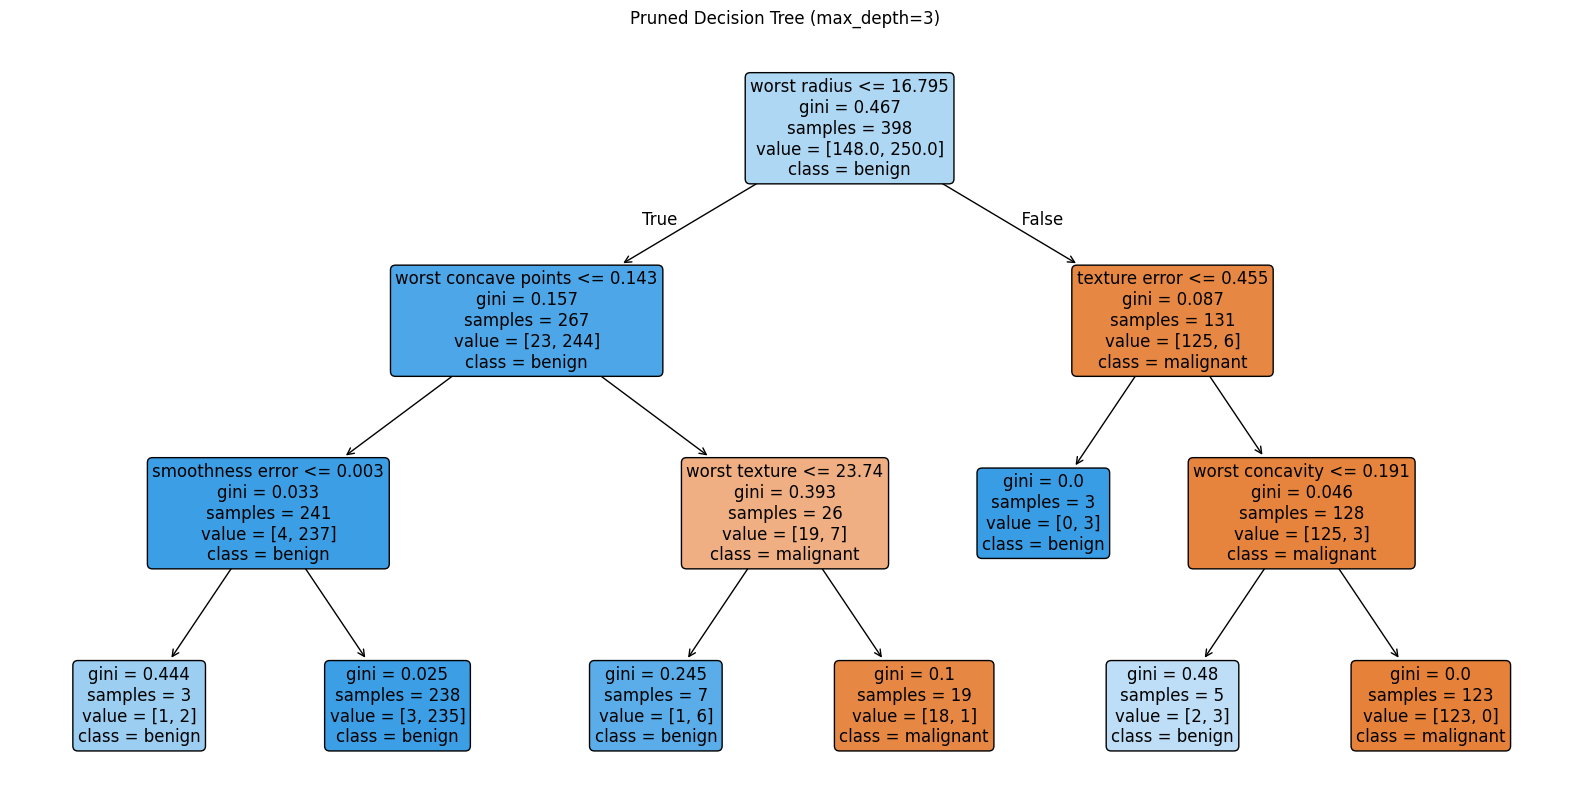

In [10]:
plt.figure(figsize=(20, 10))
plot_tree(tree_pruned,
          feature_names=cancer.feature_names,
          class_names=cancer.target_names,
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Pruned Decision Tree (max_depth=3)")
plt.show()

In [11]:
# 1. WITHOUT SCALING (WRONG WAY)
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train_log, y_train_log)
acc_unscaled = accuracy_score(y_test_log, knn_unscaled.predict(X_test_log))

print("k-NN WITHOUT SCALING")
print(f"Accuracy: {acc_unscaled:.4f}")

# 2. WITH SCALING (RIGHT WAY - Using Pipeline)
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# Use Cross-Validation to get a robust score
cv_scores_scaled = cross_val_score(knn_pipeline, X_train_log, y_train_log, cv=5, scoring='accuracy')

# Also fit on full train to get test accuracy
knn_pipeline.fit(X_train_log, y_train_log)
acc_scaled = accuracy_score(y_test_log, knn_pipeline.predict(X_test_log))

print("\nk-NN WITH SCALING (Pipeline)")
print(f"Test Accuracy: {acc_scaled:.4f}")
print(f"5-Fold CV Mean Accuracy: {cv_scores_scaled.mean():.4f} (+/- {cv_scores_scaled.std():.4f})")

k-NN WITHOUT SCALING
Accuracy: 0.9240

k-NN WITH SCALING (Pipeline)
Test Accuracy: 0.9591
5-Fold CV Mean Accuracy: 0.9674 (+/- 0.0099)


Finding optimal k using 5-Fold Cross-Validation...
Optimal k: 5 with CV Accuracy: 0.9674


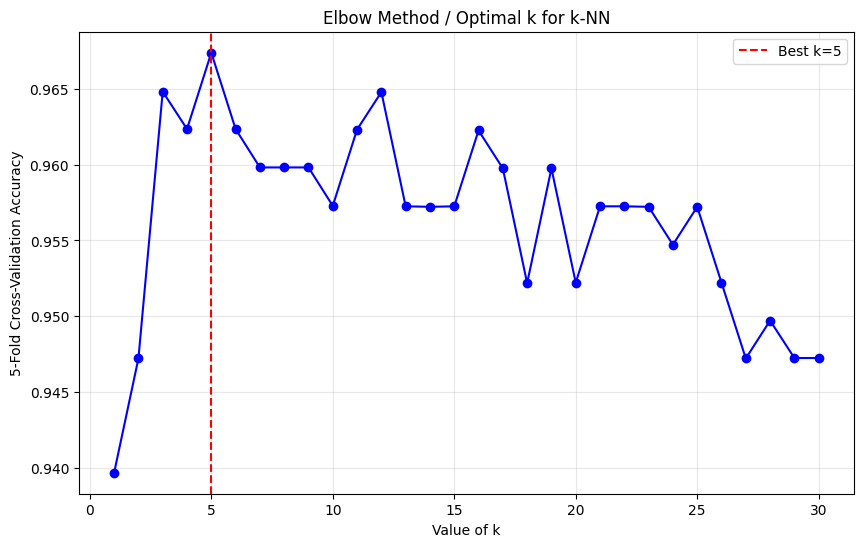

In [12]:
k_range = range(1, 31)
cv_means = []

print("Finding optimal k using 5-Fold Cross-Validation...")
for k in k_range:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe, X_train_log, y_train_log, cv=5, scoring='accuracy')
    cv_means.append(scores.mean())

best_k = k_range[np.argmax(cv_means)]
print(f"Optimal k: {best_k} with CV Accuracy: {max(cv_means):.4f}")

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(k_range, cv_means, marker='o', linestyle='-', color='b')
plt.axvline(x=best_k, color='r', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('Value of k')
plt.ylabel('5-Fold Cross-Validation Accuracy')
plt.title('Elbow Method / Optimal k for k-NN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()